In [1]:
#@title Run this to setup the libraries and download the dataset { display-mode: "form" }
# Run this every time you open the spreadsheet
%load_ext autoreload
%autoreload 2
from collections import Counter
from importlib.machinery import SourceFileLoader
import numpy as np
from os.path import join
import os
import sys
import warnings
warnings.filterwarnings("ignore")

class HiddenPrints:
    def __enter__(self):
        self._original_stdout = sys.stdout
        sys.stdout = open(os.devnull, 'w')

    def __exit__(self, exc_type, exc_val, exc_tb):
        sys.stdout.close()
        sys.stdout = self._original_stdout

with HiddenPrints():
    import nltk
    nltk.download('punkt', quiet=True)
    from nltk.stem import WordNetLemmatizer
    import seaborn as sns
    import matplotlib
    import matplotlib.pyplot as plt
    from nltk.tokenize import sent_tokenize, word_tokenize
    from nltk.stem.wordnet import WordNetLemmatizer
    from nltk.stem.porter import *
    from nltk.corpus import stopwords
    nltk.download('stopwords', quiet=True)
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    import pandas as pd
    from sklearn.metrics import multilabel_confusion_matrix
    from sklearn import metrics
    import gdown
    import string
    from wordcloud import WordCloud, STOPWORDS
    pd.set_option('max_colwidth', 100)
    from sklearn.feature_extraction.text import CountVectorizer
    nltk.download('wordnet', quiet=True)
    nltk.download('averaged_perceptron_tagger', quiet=True)

    # gdown.download('https://drive.google.com/uc?id=1q4U2gVY9tWEPdT6W-pdQpKmo152QqWLE', 'finance_train.csv', True)
    # gdown.download('https://drive.google.com/uc?id=1nIBqAsItwVEGVayYTgvybz7HeK0asom0', 'finance_test.csv', True)

    !wget 'https://storage.googleapis.com/inspirit-ai-data-bucket-1/Data/AI%20Scholars/Sessions%206%20-%2010%20(Projects)/Project%20-%20NLP%2BFinance/finance_test.csv'
    !wget 'https://storage.googleapis.com/inspirit-ai-data-bucket-1/Data/AI%20Scholars/Sessions%206%20-%2010%20(Projects)/Project%20-%20NLP%2BFinance/finance_train.csv'

    PUNCTUATION = "!#$%&()*,-./:;<=>?@^_`'{|}~"

    REPLACE_BY_SPACE_RE = re.compile('[/(){}\[\]\|@,;]')
    BAD_SYMBOLS_RE = re.compile('[^0-9a-z #+_]')
    STOPWORDS = set(stopwords.words('english'))

def clean_text(text):
    """
        text: a string
        return: modified initial string
    """
    text = text.lower() # lowercase text
    text = REPLACE_BY_SPACE_RE.sub(' ', text) # replace REPLACE_BY_SPACE_RE symbols by space in text. substitute the matched string in REPLACE_BY_SPACE_RE with space.
    text = BAD_SYMBOLS_RE.sub('', text) # remove symbols which are in BAD_SYMBOLS_RE from text. substitute the matched string in BAD_SYMBOLS_RE with nothing.
    # text = text.replace('x', '')
#    text = re.sub(r'\W+', '', text)
    text = ' '.join(word for word in text.split() if word not in STOPWORDS) # remove stopwords from text
    return text

def get_finance_train():
  df_train = pd.read_csv("finance_train.csv")
  return df_train
def get_finance_test():
  df_test = pd.read_csv("finance_test.csv")
  return df_test

def plot_word_cloud(text):
  text = text.Sentence.values
  wordcloud = WordCloud(
      width = 3000,
      height = 2000,
      background_color = 'black',
      stopwords = STOPWORDS).generate(str(text))
  fig = plt.figure(
      figsize = (10, 7),
      facecolor = 'k',
      edgecolor = 'k')
  plt.imshow(wordcloud, interpolation = 'bilinear')
  plt.axis('off')
  plt.tight_layout(pad=0)
  plt.show()

def preprocess_data(df):
  sentences = df.Sentence.values
  labels = df.Label.values
  tokenized_sentences = [word_tokenize(sentence) for sentence in sentences]
  filtered_sentences = [remove_stopwords(' '.join(tokenized_sentence)) for tokenized_sentence in tokenized_sentences]
  return filtered_sentences, labels

def plot_confusion_matrix(y_true,y_predicted):
  cm = metrics.confusion_matrix(y_true, y_predicted)
  print ("Plotting the Confusion Matrix")
  labels = ["Negative","Neutral","Positive"]
  df_cm = pd.DataFrame(cm,index =labels,columns = labels)
  fig = plt.figure(figsize=(7,6))
  res = sns.heatmap(df_cm, annot=True,cmap='Blues', fmt='g')
  plt.yticks([0.5,1.5,2.5], labels,va='center')
  plt.title('Confusion Matrix - TestData')
  plt.ylabel('True label')
  plt.xlabel('Predicted label')
  plt.show()
  plt.close()

if 'not' in STOPWORDS:
  STOPWORDS.remove('not')
if 'no' in STOPWORDS:
  STOPWORDS.remove('no')

LABEL_MAP = {0 : "negative", 1 : "neutral", 2 : "positive"}
STOPWORD_SET = set(stopwords.words('english'))
SAMPLE_SENTENCE = 'I need to remove all these meaningless stopwords.'
SAMPLE_SOLUTION = ['need', 'remove', 'meaningless', 'stopwords']

plt.rcParams.update({'font.size': 22})
print ("Train & Test Files are loaded")


Train & Test Files are loaded


In [4]:
#@title Instructor Solution

df_train = get_finance_train()
print(df_train.head())

                                                                                              Sentence  \
0                                                 Autotank Group is part of Aspo 's Systems Division .   
1  The contract includes design , construction , delivery of equipment , installation and commissio...   
2  Rapala said it estimates it will make savings of 1-2 mln eur a year by centralising its French o...   
3  The share capital of Alma Media Corporation (business ID 1944757-4)is EUR 45,031,513.80 and it i...   
4  The financial impact is estimated to be some 1.5 MEUR annual improvement in the division 's resu...   

   Label  
0      1  
1      1  
2      2  
3      1  
4      2  


In [6]:
#@title Instructor Solution

print('There are a total of {} examples in the Finance Train dataset.'.format(df_train.shape[0]))

There are a total of 2037 examples in the Finance Train dataset.


In [8]:
#@title Instructor Solution

df_test = get_finance_test()
print(df_test.head())

                                                                                              Sentence  \
0  In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operating prof...   
1  Foundries division reports its sales increased by 9.7 % to EUR 63.1 mn from EUR 57.5 mn in the c...   
2                                               Financing of the project will come mainly from China .   
3  Sukhraj Dulai , of the 2900 block of Boni Sue Court , a cul-de-sac on the city 's north side , s...   
4  Finland 's leading metals group Outokumpu said its fourth-quarter net profit more than tripled o...   

   Label  
0      2  
1      2  
2      1  
3      1  
4      2  


In [10]:
#@title Instructor Solution

print('There are a total of {} examples in the Finance Test dataset.'.format(df_test.shape[0]))

There are a total of 227 examples in the Finance Test dataset.


In [12]:
#@title Instructor Solution

print(LABEL_MAP)

{0: 'negative', 1: 'neutral', 2: 'positive'}


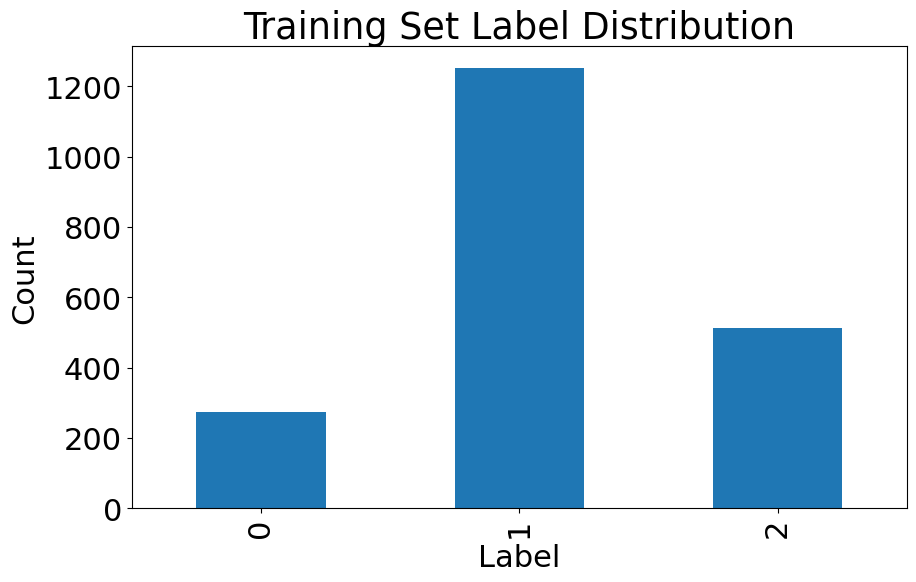

In [14]:
#@title Instructor Solution
fig = plt.figure(figsize=(10,6))
plt.title('Training Set Label Distribution')
plt.xlabel('Sentiment Label')
plt.ylabel('Count')
df_train.groupby('Label').Sentence.count().plot.bar(ylim=0)
plt.show()

In [16]:
#@title Instructor Solution
negative_data = df_train[df_train['Label'] == 0]

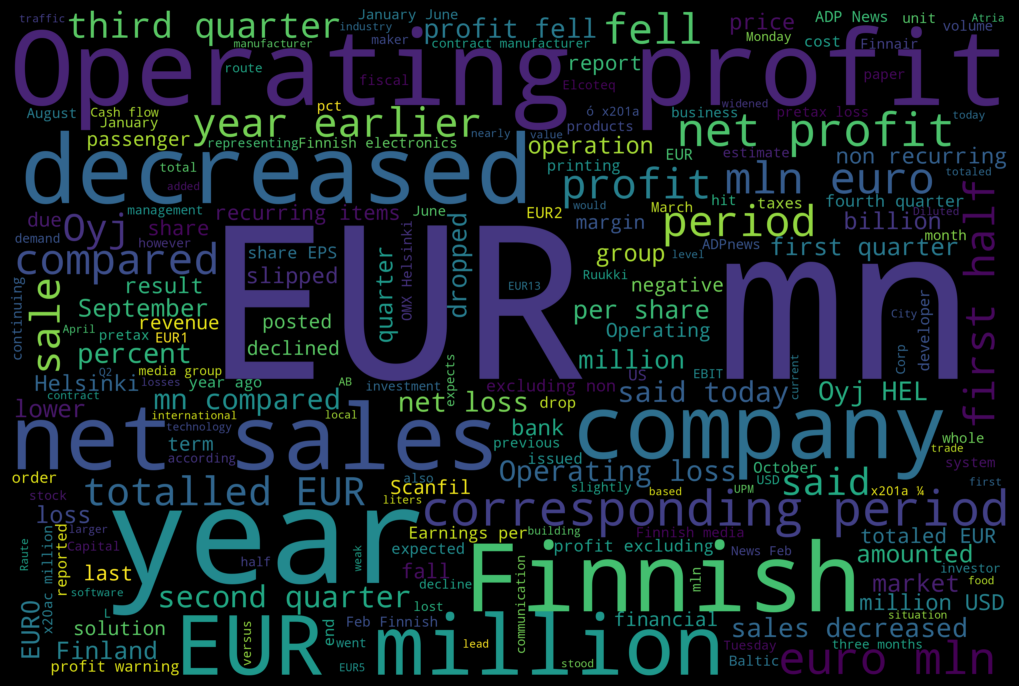

In [18]:
#@title Instructor Solution

plot_word_cloud(negative_data)

In [20]:
#@title Instructor Solution

positive_data = df_train[df_train['Label'] == 2]

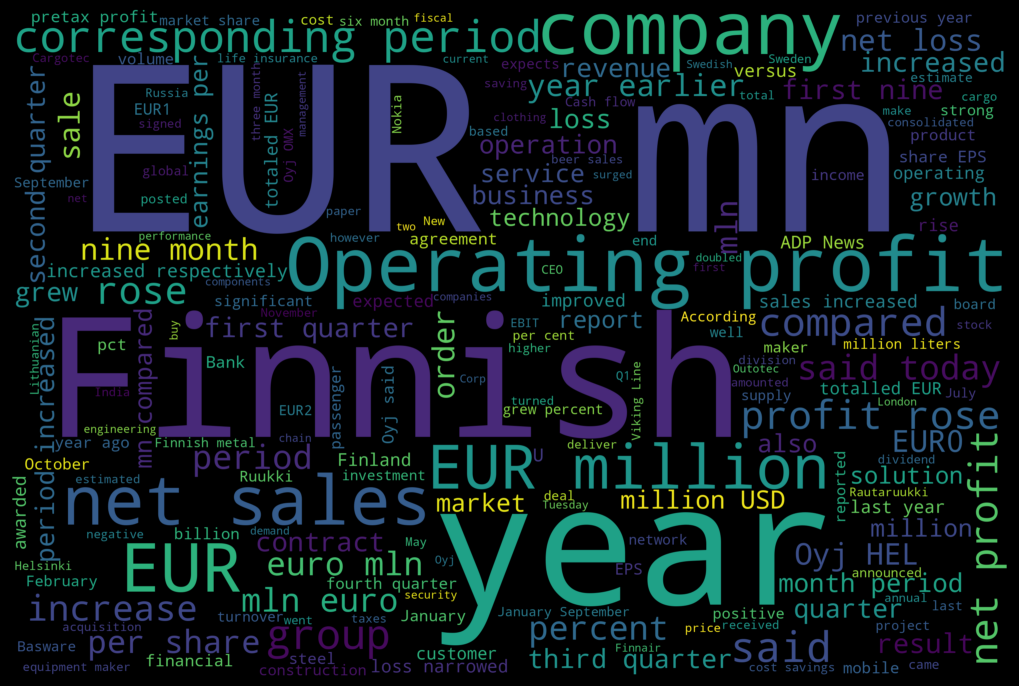

In [22]:
#@title Instructor Solution

plot_word_cloud(positive_data)

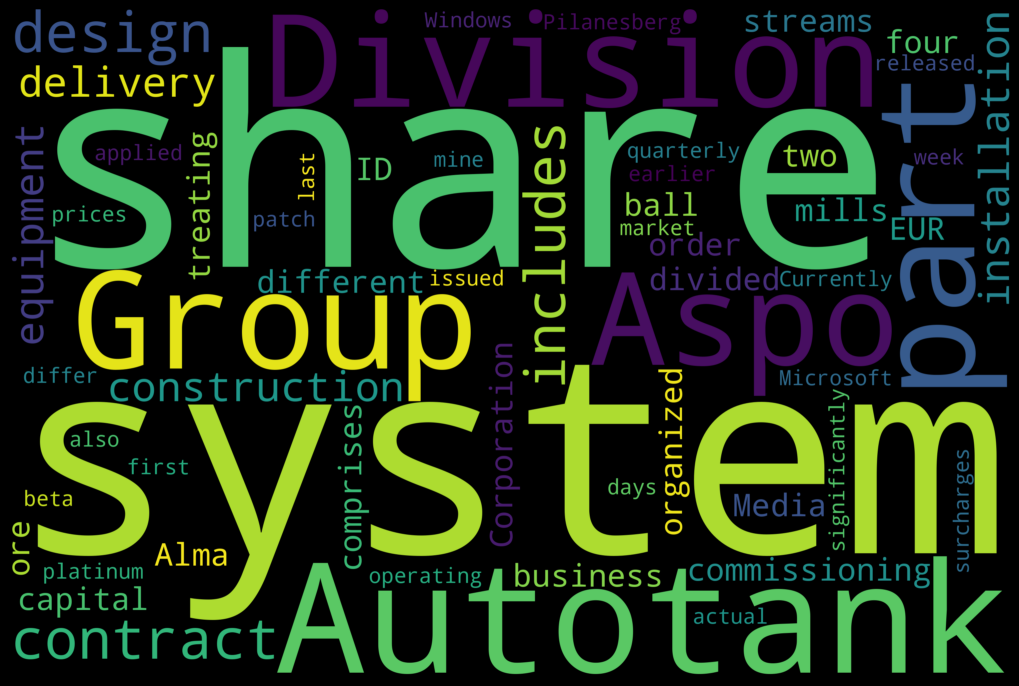

In [24]:
#@title Instructor Solution

neutral_data = df_train[df_train['Label'] == 1]
plot_word_cloud(neutral_data)

In [27]:
#@title Instructor Solution

sample_sentence = 'There, is-! a# lo?t of< pu>=nctuat-io!n he~re!'
print(sample_sentence)

There, is-! a# lo?t of< pu>=nctuat-io!n he~re!


Now, we will use the `regex` library named `re` to filter out the punctuation. To do so, we need to make a `regex` object using the function `re.compile(f"[{PUNCTUATION}]")` and passing in our `PUNCTUATION` string as shown. Don't worry about the weird notation, as this is just a means of properly creating the regular expression object! Save the value this function returns in a variable named `PUNCTUATION_RE`.

In [29]:
#@title Instructor Solution

PUNCTUATION_RE = re.compile(f"[{PUNCTUATION}]")

In [31]:
#@title Instructor Solution

filtered_sample_sentence = PUNCTUATION_RE.sub("", sample_sentence)
print(filtered_sample_sentence)

There is a lot of punctuation here


In [35]:
#@title Instructor Solution

print(STOPWORD_SET)

{"you'd", 'why', 'no', "wouldn't", 'she', "you'll", 'there', 'don', 'which', 'through', 'couldn', 'hadn', 'during', 'he', 'shouldn', "don't", "hadn't", 'ma', 'are', 'here', "that'll", 'were', "weren't", 'do', 'once', 'yours', 'their', "haven't", 'until', 'just', 'needn', 'isn', 'my', 'over', 'aren', 'our', 'ours', 'has', 'theirs', 'both', 'y', "isn't", "should've", "aren't", 'doing', 'myself', 'yourselves', "it's", 'its', 'own', 're', 'her', 'that', 'so', 'in', 'whom', 'nor', 't', "shouldn't", 'more', "hasn't", 'hasn', 'between', 'who', 'ourselves', 'again', 'because', 'below', 'not', 'some', 'himself', 'herself', 'be', 'ain', 'on', 'had', 'into', 'down', 'didn', 'them', 'an', "mustn't", 'and', 'other', 'if', 'weren', 'any', 'few', "mightn't", 'wouldn', "didn't", 'him', 'it', 'those', 'off', "won't", 'then', 'll', 'm', "shan't", 'to', 'a', 'or', 've', 'they', 'as', 'but', 'for', 'o', 'at', 'am', "she's", 'before', 'this', 'such', "you've", 'itself', 'should', 'of', 'you', 'against', "n

In [36]:
#@title Check If Stopword { run: "auto", vertical-output: true, display-mode: "form" }
word = "than" #@param {type:"string"}
word = word + "\""
if not word: raise Exception('Please enter a word')
eng_stopwords = set(stopwords.words('english'))
if word[:-1].lower().strip() in eng_stopwords: print('Yes, \"{}'' is a stopword.'.format(word))
else: print('No,\"{}'' is NOT a stopword.'.format(word))



Yes, "than" is a stopword.


In [37]:
#@title Sample Input and Output

print(f'Sample Input:\t{SAMPLE_SENTENCE}')
print(f'Sample Output:\t{SAMPLE_SOLUTION}')

Sample Input:	I need to remove all these meaningless stopwords.
Sample Output:	['need', 'remove', 'meaningless', 'stopwords']


In [39]:
#@title Instructor Solution
def remove_stopwords(full_sentence):
  PUNCTUATION_RE = re.compile("[%s]" % PUNCTUATION)
  no_punctuation_sentence = PUNCTUATION_RE.sub(" ", full_sentence)
  words = word_tokenize(no_punctuation_sentence)
  filtered_sentence = []
  for w in words:
      if w.lower() not in STOPWORD_SET:
          filtered_sentence.append(w)
  return filtered_sentence

In [40]:
print(SAMPLE_SENTENCE)

I need to remove all these meaningless stopwords.


In [41]:
remove_stopwords(SAMPLE_SENTENCE)

LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [42]:
#@title Instructor Solution

train_sentences, train_labels = preprocess_data(df_train)
for sentence in train_sentences[:3]:
    print(sentence)

LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [43]:
#@title Instructor Solution

test_sentences, test_labels = preprocess_data(df_test)
for sentence in test_sentences[:3]:
    print(sentence)

LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [ ]:
# List of sentences
all_sentences = ["Google AI made remarkable achievements in 2019.", "Google Stock was at its all time high"]

# Create instance of CountVectorizer() object
vectorizer = CountVectorizer()

In [ ]:
# Tokenizes the text and builds the vocabulary
vectorizer.fit(all_sentences)

In [ ]:
print(vectorizer.vocabulary_)

In [ ]:
# Encode sentences as a vectors
bag_of_words_matrix = vectorizer.transform(all_sentences).toarray()

# Print vectors
print(bag_of_words_matrix)

In [ ]:
#@title Instructor Solution

print(bag_of_words_matrix.shape)

In [ ]:
#@title Instructor Solution
def train_model(train_sentences, train_labels):
  """
  param: train_sentences - list of pre-processed sentences to train on
  param: train_labels - list of labels (positive, neutral, negative) for each sentence in train_sentences
  return: the vectorizer, the Logistic Regression model
  """
  train_sentences = [" ".join(t) for t in train_sentences]
  train_labels = [l for l in train_labels]

  # Initialize CountVectorizer
  vectorizer = CountVectorizer()

  # Get the vector representation of train_sentences using the .fit() and .transform() methods
  vectorizer.fit(train_sentences)
  train_vect = vectorizer.transform(train_sentences)
  # Alternative one-line solution: train_vect = vectorizer.fit_transform(train_sentences)

  # Initialize a Logistic Regression model
  model = LogisticRegression()

  # Train with train_vect and train_labels using the .fit() method of LogisticRegression
  model.fit(train_vect, train_labels)

  return model, vectorizer

In [ ]:
#@title Instructor Solution

model, train_vectorizer = train_model(train_sentences, train_labels)

In [ ]:
#@title Instructor Solution
def predict(test_sentences, test_labels, vectorizer, model):
  """
  param: test_sentences - list of pre-processed sentences to test the model
  param: vectorizer - the CountVectorizer from the train_model function
  param: model - the Logistic Regression model from the train_model function
  return: preds - the predictions of the model based on test_sentences
  """
  test_sentences = [" ".join(t) for t in  test_sentences]

  # Get the vector representation of test_sentences using vectorizer's .transform method (no need to use .fit!)
  test_vect = vectorizer.transform(test_sentences)

  # Predict the labels of test_sentences using the model's predict method on test_vect
  preds = model.predict(test_vect)

  acc = metrics.accuracy_score(test_labels, preds)
  return preds, acc

In [ ]:
#@title Instructor Solution

y_predictions, test_accuracy = predict(test_sentences, test_labels, train_vectorizer, model)
print(f'The model had an accuracy of {test_accuracy:.2%} on the test dataset')

In [ ]:
plot_confusion_matrix(test_labels, y_predictions)